<a href="https://colab.research.google.com/github/DengAchiek/Data-science/blob/main/C10_M04_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Lab: RNN with Forecasting

### Wind Turbine Power Prediction with RNN

This lab uses a Recurrent Neural Network to predict wind turbine power output.
* [Data link](https://www.kaggle.com/code/ahmedfathygwely/wind-turbine-dataset-machine-learning-rnn-times/input)

### Step 0: Load libraries & Data

In [2]:
# Step 0: Load libraries & Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import math

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Load the data
df = pd.read_csv('/content/T1.csv')

In [3]:

# Display basic information
print("Data Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nDataset Info:")
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

Data Shape: (50530, 5)

First 5 rows:
          Date/Time  LV ActivePower (kW)  Wind Speed (m/s)  \
0  01 01 2018 00:00           380.047791          5.311336   
1  01 01 2018 00:10           453.769196          5.672167   
2  01 01 2018 00:20           306.376587          5.216037   
3  01 01 2018 00:30           419.645905          5.659674   
4  01 01 2018 00:40           380.650696          5.577941   

   Theoretical_Power_Curve (KWh)  Wind Direction (°)  
0                     416.328908          259.994904  
1                     519.917511          268.641113  
2                     390.900016          272.564789  
3                     516.127569          271.258087  
4                     491.702972          265.674286  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Date/Time  

### Step 1: Prepare the data

In [6]:
# Prepare the data

# Convert 'Date/Time' to datetime and sort sequentially
df['Date/Time'] = pd.to_datetime(df['Date/Time'], format='%d %m %Y %H:%M')
df = df.sort_values('Date/Time').reset_index(drop=True)

# Target feature for time-series forecasting: LV ActivePower (kW)
target_data = df[['LV ActivePower (kW)']].values

# Scale data to range [0, 1] for optimal LSTM performance
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(target_data)

### Step 2: Create sequences

In [7]:
# Create sequences

def create_sequences(data, sequence_length):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i + sequence_length])
        y.append(data[i + sequence_length])
    return np.array(X), np.array(y)

# Define sequence length (number of past time steps used to predict the next step)
SEQUENCE_LENGTH = 24

X, y = create_sequences(scaled_data, SEQUENCE_LENGTH)
print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (50506, 24, 1), y shape: (50506, 1)


### Step 3: Split the data

In [8]:
# Split the data (Chronological split to prevent data leakage)

train_size = int(len(X) * 0.8)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Train shape: X={X_train.shape}, y={y_train.shape}")
print(f"Test shape:  X={X_test.shape}, y={y_test.shape}")

Train shape: X=(40404, 24, 1), y=(40404, 1)
Test shape:  X=(10102, 24, 1), y=(10102, 1)


### Step 4: Build the RNN Model

In [9]:
# Build the RNN Model

model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Train the model

In [10]:
# Train the model

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ModelCheckpoint('best_rnn_model.keras', monitor='val_loss', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - loss: 0.0174 - mae: 0.0796 - val_loss: 0.0070 - val_mae: 0.0611
Epoch 2/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - loss: 0.0080 - mae: 0.0556 - val_loss: 0.0056 - val_mae: 0.0519
Epoch 3/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - loss: 0.0066 - mae: 0.0504 - val_loss: 0.0055 - val_mae: 0.0506
Epoch 4/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.0061 - mae: 0.0490 - val_loss: 0.0055 - val_mae: 0.0498
Epoch 5/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.0058 - mae: 0.0478 - val_loss: 0.0056 - val_mae: 0.0500
Epoch 6/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.0057 - mae: 0.0470 - val_loss: 0.0054 - val_mae: 0.0500
Epoch 7/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - loss: 0.0055 - mae: 0.0461 - val_loss: 0.0054 - val_mae: 0.0494
Epoch 8/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 10s 18ms/step - loss: 0.0054 - mae: 0.0453 - val_loss: 0.0055 - val_mae: 0.0508
Epoch 9/50
569/569 ━━━━━━━━━━━━━━━━━━━━ 

### Step 6: Evaluate on the test data and visualize the results

316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Test RMSE: 233.4688
Test R² Score: 0.9697


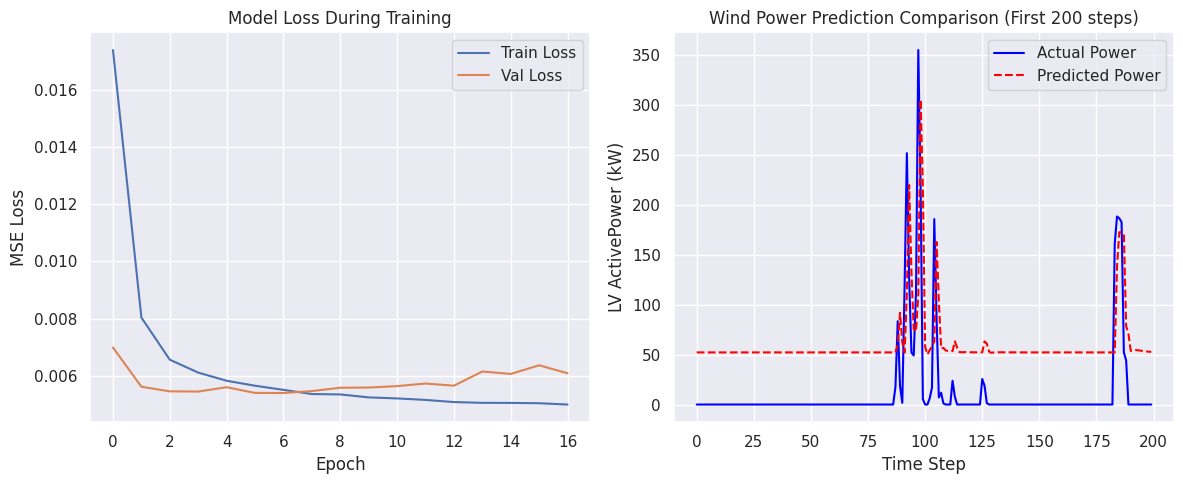

In [12]:
import seaborn as sns
sns.set(style="darkgrid")
# Evaluate and visualize

# Make predictions on test set
y_pred_scaled = model.predict(X_test)

# Inverse transform to get actual power values
y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

# Calculate metrics
rmse = math.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
r2 = r2_score(y_test_actual, y_pred_actual)

print(f"Test RMSE: {rmse:.4f}")
print(f"Test R² Score: {r2:.4f}")

# Plot Training vs Validation Loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss During Training')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()

# Plot Actual vs Predicted Output (First 200 test samples for clarity)
plt.subplot(1, 2, 2)
plt.plot(y_test_actual[:200], label='Actual Power', color='blue')
plt.plot(y_pred_actual[:200], label='Predicted Power', color='red', linestyle='--')
plt.title('Wind Power Prediction Comparison (First 200 steps)')
plt.xlabel('Time Step')
plt.ylabel('LV ActivePower (kW)')
plt.legend()

plt.tight_layout()
plt.show()